# Case Study 10 — Finding BNPL Fraud Rings with Graph Communities, and Counting the Cost to Good Users

**Priority:** ★★ Good to have · **Reference:** Case Study 10 — *Simpl: a BNPL ML platform for fraud rings, underwriting and repayment support* (`indian_fintech_data_science_case_studies.md`)
**Audience:** Head of Risk, Fraud Strategy, Growth (onboarding funnel), Finance
**Data:** ⚠️ **SYNTHETIC** (D-10-01). BNPL user data are confidential; this is a calibrated simulation.
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs10_bnpl_fraud_rings_graph.ipynb`

## 0. Executive Summary for Business

*(Synthetic data built on Simpl's documented design; Simpl disclosed no numbers. Written after the analysis.)*

- **The question:** can linking new BNPL users by shared phones, addresses, bank accounts and email patterns stop fraud rings at onboarding, without declining genuine families and hostel residents?
- **Yes. The links carry the signal, and the simplest link features capture most of it.** Defaulters cluster far more than chance (45% vs 9%, permutation p = 0.002), and that clustering is driven by fraud, not by genuine credit stress. Adding "how many earlier users share this device / address / bank account / email pattern" lifts fraud recall at a 1% decline budget from **2% to 51%** (AUC 0.73 → 0.83, p < 0.0001), and ring-member recall to **84%**. Full multi-hop **communities add little on top** (AUC +0.009, p = 0.19).
- **The graph must be built carefully or it punishes good users.**
  - Without pruning, **12.9% of genuine users** land in "suspicious" communities of 4+ (one has 2,394 people).
  - Dropping attributes shared by more than 10 users (hostels, offices) cuts that to **4.8%** while keeping **98%** of ring members.
  - A placeholder device ID from an old SDK, left uncleaned, would have glued 9,042 users together.
- **Where to draw the line:** total cost (fraud + credit loss + ₹1,200 lifetime value per wrongly declined good user) is lowest when declining the riskiest **0.5% of applicants**: half of all fraudsters stopped, almost no good users declined, ≈ **₹0.8 crore/month saved at 5 lakh sign-ups**. Declining more than 2% *costs* money.
- **Other findings:**
  - Real-time (hourly) graph updates beat a nightly batch only for rings signing up the same day (90% vs 84% caught); overall the difference is not significant (p = 0.36).
  - Training on **confirmed fraud** instead of first-payment default improves AUC by +0.05 (p ≈ 3e-9).
  - First-week spending behaviour is the strongest signal of all (AUC 0.99), but it arrives after the bust-out.
- **I recommend:** at onboarding, decline (or give a ₹500 starter limit to) the top 0.5% by a model with hub-pruned link counts. Keep community features as an investigation tool. Label defaulters as fraud vs credit stress. Watch the decline rate in shared-address communities as a fairness guardrail.

## 1. The Problem in Simple English

A buy-now-pay-later (BNPL) company gives shoppers instant credit at checkout. A common attack is a **fraud ring**: a gang creates dozens of accounts, often with the same few phones, delivery addresses and bank accounts, uses each account's full limit within days, and never repays. Looked at one at a time, each account seems like an ordinary new customer. Looked at **as a group**, they are obvious: 20 "different" people sharing three phones and two addresses.

That is what Simpl's **graph ML** does: connect accounts that share identity details and look at the **communities** they form. The catch is that genuine people share things too. Families share a phone, and hostel, PG and office residents share an address. A careless graph lumps hundreds of genuine users into "suspicious" clusters and declines them. The documented metric is therefore the **precision–recall trade-off and its impact on good users**.

This notebook asks:
- How much do graph communities add beyond single-account checks?
- How should the graph be built so it does not punish families and hostels?
- Does real-time graph updating beat a nightly batch?
- Where should the decline line be drawn, counting the cost to good users?

## 2. Reference from the Case File

### (a) What Simpl did — *documented*

| Item | Documented fact (quoted from the reference file) |
|---|---|
| Business | Instant checkout credit across "**26,000+ merchants**"; stop fraud "including account takeover and identity theft" in real time; set limits at onboarding; help users who struggle to repay |
| Data | Current transaction payload; "one year of user history"; identity ("email IDs, phone numbers", batch analysis); real-time velocity and amount monitoring |
| Approach | "Rules and filters, then ML models, then neural networks"; "**Graph ML** to find fraud communities"; batch models in Airflow |
| ML / metrics | Neural network combining payload + history; graph ML for communities; "**precision–recall trade-off and impact on 'good users'**". **No numbers** |
| Tech | Apache Flink (**70–80 ms SLA**), Airflow, DynamoDB feature store, SageMaker; 28 data scientists + 16 data engineers |
| Impact | **Not publicly disclosed** |

**Source:** TrueFoundry, "True ML Talks #5" with Sheekha Verma (Director of Data Science, Simpl), 6 Aug 2024 — https://www.truefoundry.com/blog/machine-learning-platform-simpl

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| Data | 120,000 users onboarded over 13 weeks with device, phone, email pattern, delivery address, IP block and repayment bank account. 70 fraud rings (≈ 730 accounts) + ≈ 500 lone fraudsters. Genuine sharing: 10% families (shared device/address), 12% hostel/PG/office address hubs (Zipf-sized), carrier IP blocks. Observed label: **first-payment default (FPD)**, which mixes fraud with genuine credit stress (3% of good users). |
| Statistics added (none disclosed) | Permutation test that defaults cluster in communities; hub-pruning sensitivity (collateral damage to good users); feature-tier comparison (individual → 1-hop links → communities → first-week behaviour) with DeLong + Holm; label choice (FPD vs confirmed fraud); batch vs real-time graph (McNemar); cluster-bootstrap precision by community; cost-optimal decline threshold including good-user lifetime value |

### (c) How the industry uses this

Identity-graph fraud detection is standard across Indian lending and BNPL: Simpl, LazyPay, ZestMoney (before its shutdown), Slice, KreditBee and MoneyView all link applications by device, phone, address and bank account. Bureaus offer it as a service (CRIF and TransUnion CIBIL application-fraud consortia; Experian Hunter). The same technique finds collusive merchants (QR fraud), referral abuse and synthetic identities. The hard part everywhere is **not finding rings but not hurting genuine shared households**.

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | Which new users should be declined (or given a minimal limit) at onboarding, and how many good users is that worth losing? |
| Analytical | Do graph-community features computed at onboarding identify fraud beyond single-account and direct-link features, without sweeping genuine households and hostels into suspicious clusters? |

**Hypotheses**
- **H1 (clustering):** H0: defaults are spread over communities as if at random (label permutation test).
- **H2 (tiers):** H0: AUC(+ communities) = AUC(+ 1-hop links), and AUC(+ 1-hop) = AUC(individual) (DeLong, Holm).
- **H3 (real time):** H0: an hourly-updated graph catches the same frauds as a nightly-batch graph at a fixed decline budget (McNemar).
- **H4 (labels):** training on FPD vs true fraud labels gives the same fraud recall (reported descriptively; true fraud labels exist only in the simulation).

**Primary metric:** recall of fraudsters at a fixed decline budget (1% of applicants). **Guardrail ("impact on good users"):** good users declined per fraudster stopped, and the share of genuine users placed in suspicious communities. **Decision metric:** total ₹ cost (fraud loss + credit loss + lost good-user value). **Design:** train on users onboarded in weeks 1–7, **test on weeks 9–13**. Every graph feature uses only users onboarded **before** the applicant.

In [1]:
import sys, warnings, importlib, os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import rankdata
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.ensemble import HistGradientBoostingClassifier as HGB
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, average_precision_score
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public BNPL / application-fraud data with shared identity attributes | **None.** Lending applications are personal data (DPDP Act); public credit sets (UCI German/Taiwan) have no identity links. Elliptic/Bitcoin graph data is unrelated (crypto transactions). |
| **Decision** | Synthetic onboarding data with rings and genuine sharing (D-10-01) |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs10.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 10 (Simpl-style BNPL fraud rings found with graph communities)
====================================================================================================
THIS DATA IS SYNTHETIC. BNPL user and transaction data are confidential.

A checkout-credit (BNPL) provider onboards users over 13 weeks. Each user has identity attributes
(device, phone, email, delivery address, IP block, repayment bank account). Genuine users share some
attributes naturally (families share devices/addresses; hostels, PGs and offices are address HUBS
shared by dozens of unrelated people; carrier IP blocks are shared by thousands).
Fraud:
  * RINGS (bust-out / synthetic identity): groups of 4-40 accounts created by one gang, re-using a
    few devices, addresses, email patterns and bank accounts; they max out their limits within days
    and never repay. A ring is invisible one account at a time and obvious as a group.
  * Lone first-party fraud and account takeover (ATO): individual, no links.
Outcome observed by the lender: FIRST-PAYMENT DEFAULT (FPD) - not paid 30 days after the first due date.
FPD mixes fraud (intent never to pay) with genuine credit stress (~3% of good users).

Calibration anchors (reference file, Case Study 10): Simpl serves "26,000+ merchants"; fraud includes
"account takeover and identity theft"; "graph ML to find fraud communities"; real-time SLA 70-80 ms;
metrics "precision-recall trade-off and impact on good users" (no numbers disclosed).
Rates are our assumptions (decision.md D-10-02). Hidden truth columns start with "_".

Output: data/cs10/users.csv.gz
"""
import os
import numpy as np
import pandas as pd

SEED = 42
START = pd.Timestamp("2026-01-05"); DAYS = 91


def generate(seed=SEED):
    rng = np.random.default_rng(seed)
    n = 120_000
    day = np.sort(rng.uniform(0, DAYS, n))
    uid = np.array([f"U{i:06d}" for i in range(n)])
    # ---------- genuine attributes ----------
    dev = np.array([f"DV{i:06d}" for i in range(n)]); addr = np.array([f"AD{i:06d}" for i in range(n)])
    fam = rng.random(n) < 0.10                                                   # family members share device + address
    src = np.maximum(np.arange(n) - rng.integers(1, 40, n), 0)
    dev[fam] = dev[src[fam]]; addr[fam] = addr[src[fam]]
    hub = rng.random(n) < 0.12                                                   # hostels / PGs / offices
    hw = 1 / np.arange(1, 2001) ** 0.8; hw /= hw.sum()                              # hub sizes: few big hostels/offices, many small PGs
    addr[hub] = [f"HUB{h:04d}" for h in rng.choice(2000, hub.sum(), p=hw)]
    ipb = np.array([f"IPB{x:04d}" for x in rng.integers(0, 3000, n)])            # carrier IP blocks (huge hubs)
    phone = np.array([f"PH{i:06d}" for i in range(n)]); email_pat = np.array([f"EP{i:06d}" for i in range(n)])
    bank = np.array([f"BA{i:06d}" for i in range(n)]); famb = fam & (rng.random(n) < 0.5); bank[famb] = bank[src[famb]]   # spouses repay from one account
    age_days_phone = np.where(rng.random(n) < 0.15, rng.gamma(1.5, 30, n), rng.gamma(2.0, 400, n))   # SIM vintage; 15% of genuine users have new numbers
    limit = np.round(rng.choice([1500, 3000, 5000, 10000], n, p=[0.35, 0.35, 0.2, 0.1]), 0)
    spend7 = np.round(limit * np.clip(rng.beta(1.3, 4, n), 0.02, 1), 0)
    n_tx7 = 1 + rng.poisson(1.5, n)
    merchants7 = np.minimum(n_tx7, 1 + rng.poisson(0.7, n))
    night = rng.binomial(n_tx7, 0.06)
    kind = np.full(n, "genuine", dtype=object)
    fpd_p = np.full(n, 0.03)                                                     # genuine credit stress
    # ---------- fraud rings ----------
    ring_id = np.full(n, "", dtype=object)
    cand = np.flatnonzero(~fam & ~hub); used = set()
    for r in range(70):
        size = int(np.clip(rng.lognormal(np.log(10), 0.6), 4, 40)); d0 = rng.uniform(0, DAYS - 10)
        win = [i for i in cand[(day[cand] > d0) & (day[cand] < d0 + rng.uniform(3, 20))] if i not in used]      # members sign up over 3-20 days
        if len(win) < 4: continue
        pool = np.sort(rng.choice(win, min(size, len(win)), replace=False)); used.update(pool.tolist())
        ndev, naddr, nbank = max(1, size // 6), max(1, size // 5), max(1, size // 8)
        sharing = rng.uniform(0.5, 0.95)                                         # how much the gang re-uses attributes
        sh = rng.random(len(pool)) < sharing
        dev[pool[sh]] = rng.choice([f"RD{r:02d}{j}" for j in range(ndev)], sh.sum())
        sh2 = rng.random(len(pool)) < sharing; addr[pool[sh2]] = rng.choice([f"RA{r:02d}{j}" for j in range(naddr)], sh2.sum())
        sh3 = rng.random(len(pool)) < sharing; bank[pool[sh3]] = rng.choice([f"RB{r:02d}{j}" for j in range(nbank)], sh3.sum())
        sh4 = rng.random(len(pool)) < 0.6; email_pat[pool[sh4]] = f"REP{r:02d}"     # e.g., rahul.k1@, rahul.k2@ ... same pattern
        ipb[pool] = np.where(rng.random(len(pool)) < 0.5, f"IPB{rng.integers(3000):04d}", ipb[pool])
        age_days_phone[pool] = np.where(rng.random(len(pool)) < 0.6, rng.gamma(1.2, 40, len(pool)), rng.gamma(2.0, 250, len(pool)))   # mostly fresh SIMs; some bought aged
        spend7[pool] = np.round(limit[pool] * rng.uniform(0.75, 1.0, len(pool)), 0); n_tx7[pool] = 2 + rng.poisson(4, len(pool))
        merchants7[pool] = np.minimum(n_tx7[pool], 1 + rng.poisson(2.5, len(pool))); night[pool] = rng.binomial(n_tx7[pool], 0.2)
        kind[pool] = "ring"; ring_id[pool] = f"R{r:02d}"; fpd_p[pool] = 0.93
    # ---------- lone first-party fraud / ATO ----------
    lone = np.flatnonzero((kind == "genuine") & (rng.random(n) < 0.004))
    kind[lone] = "lone_fraud"; fpd_p[lone] = 0.85
    spend7[lone] = np.round(limit[lone] * rng.uniform(0.6, 1.0, len(lone)), 0); n_tx7[lone] = 2 + rng.poisson(3, len(lone)); night[lone] = rng.binomial(n_tx7[lone], 0.15)
    age_days_phone[lone] = rng.gamma(1.5, 150, len(lone))
    # genuine heavy users look a bit like fraud (hard negatives)
    heavy = (kind == "genuine") & (rng.random(n) < 0.05); spend7[heavy] = np.round(limit[heavy] * rng.uniform(0.7, 1.0, heavy.sum()), 0); n_tx7[heavy] += rng.poisson(3, heavy.sum())
    fpd = (rng.random(n) < fpd_p).astype(int)
    df = pd.DataFrame({"user_id": uid, "onboard_ts": START + pd.to_timedelta(day * 86400, unit="s"), "device_id": dev, "phone_id": phone, "email_pattern": email_pat,
                       "address_id": addr, "ip_block": ipb, "repay_bank_acct": bank, "sim_age_days": age_days_phone.round(), "credit_limit_inr": limit,
                       "spend_first7d_inr": spend7, "n_txn_first7d": n_tx7, "n_merchants_first7d": merchants7, "night_txn_first7d": night,
                       "fpd": fpd, "_kind": kind, "_ring": ring_id})
    # data-quality defects
    df.loc[df.sample(n=1500, random_state=seed).index, "device_id"] = "00000000"               # placeholder device id from an old SDK (a fake hub!)
    df.loc[df.sample(frac=0.01, random_state=seed + 1).index, "address_id"] = np.nan
    df = pd.concat([df, df.sample(n=500, random_state=seed + 2)], ignore_index=True)          # duplicated onboarding events
    return df


if __name__ == "__main__":
    here = os.path.dirname(os.path.abspath(__file__)); os.makedirs(os.path.join(here, "cs10"), exist_ok=True)
    d = generate(); d.to_csv(os.path.join(here, "cs10", "users.csv.gz"), index=False)
    dd = d.drop_duplicates("user_id")
    print(len(dd), "users |", dd._kind.value_counts().to_dict(), "| rings", dd._ring.replace("", np.nan).nunique())
    print("FPD by kind", dd.groupby("_kind").fpd.mean().round(3).to_dict(), "overall", dd.fpd.mean().round(4))

Overwriting data/generate_cs10.py


In [3]:
os.makedirs("data/cs10", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs10 as gen; importlib.reload(gen)
raw = gen.generate(seed=SEED); raw.to_csv("data/cs10/users.csv.gz", index=False)
print(f"{len(raw):,} rows | {raw.user_id.nunique():,} unique users")
raw.drop(columns=["_kind", "_ring"]).sample(3, random_state=SEED).T

120,500 rows | 120,000 unique users


,11704,15199,74722
user_id,U011704,U015199,U074722
onboard_ts,2026-01-13 23:04:55.419790526,2026-01-16 14:21:12.297769872,2026-03-02 17:16:15.545936302
device_id,DV011704,DV015199,DV074722
phone_id,PH011704,PH015199,PH074722
email_pattern,EP011704,EP015199,EP074722
address_id,HUB0988,AD015199,AD074722
ip_block,IPB2359,IPB1529,IPB0323
repay_bank_acct,BA011704,BA015199,BA074722
sim_age_days,601.0000,495.0000,"1,677.0000"
credit_limit_inr,5000,5000,10000


| Parameter | Value | Basis |
|---|---|---|
| Users | 120,000 onboarded over 13 weeks; limits ₹1,500–10,000 | Our assumption; documented 26,000+ merchants |
| Fraud rings | 70 gangs of 4–40 accounts formed over 3–20 days; re-use of a few devices, addresses, bank accounts (50–95% re-use), sequential email patterns; fresh SIMs; 75–100% of limit spent in week 1; 93% FPD | **Documented** "fraud communities", "identity theft"; sizes ours |
| Lone fraud / ATO | ≈ 0.4% of users, no links, high spend; 86% FPD | **Documented** "account takeover" |
| Genuine sharing | 10% families (device + address; half share a bank account); 12% at Zipf-sized hostel/PG/office address hubs; 3,000 carrier IP blocks | Realism: the "good users" problem |
| Label | FPD = not paid 30 days after the first due date; 3% of genuine users default for credit reasons | Realism |
| DQ issues | 1,500 users with a placeholder device ID `00000000` (old SDK); 1% missing address; 500 duplicate onboarding events | Built-in messiness |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("user_id, onboard_ts", "User and onboarding time"), ("device_id, phone_id, email_pattern", "Identity tokens (email_pattern groups look-alike addresses such as rahul.k1@ / rahul.k2@)"),
    ("address_id, ip_block, repay_bank_acct", "Delivery address, carrier IP block, bank account used for repayment"), ("sim_age_days", "Age of the SIM (fresh SIMs are risky)"),
    ("credit_limit_inr", "Limit assigned at onboarding"), ("spend_first7d_inr, n_txn_first7d, n_merchants_first7d, night_txn_first7d", "First-week behaviour (known only 7 days after onboarding)"),
    ("fpd", "First-payment default (the label the lender observes)"), ("_kind, _ring", "HIDDEN truth: genuine / ring / lone_fraud, and ring id (evaluation only)"),
], columns=["field(s)", "meaning"])
dd.to_csv("data/cs10/data_dictionary.csv", index=False); dd

,field(s),meaning
0,"user_id, onboard_ts",User and onboarding time
1,"device_id, phone_id, email_pattern",Identity tokens (email_pattern groups look-ali...
2,"address_id, ip_block, repay_bank_acct","Delivery address, carrier IP block, bank accou..."
3,sim_age_days,Age of the SIM (fresh SIMs are risky)
4,credit_limit_inr,Limit assigned at onboarding
5,"spend_first7d_inr, n_txn_first7d, n_merchants_...",First-week behaviour (known only 7 days after ...
6,fpd,First-payment default (the label the lender ob...
7,"_kind, _ring","HIDDEN truth: genuine / ring / lone_fraud, and..."


## 5. Data Quality Checks

In [5]:
df = pd.read_csv("data/cs10/users.csv.gz", parse_dates=["onboard_ts"], dtype={"device_id": str})
dev_counts = df.drop_duplicates("user_id").device_id.value_counts()
checks = {"duplicate user_id (onboarding events)": int(df.user_id.duplicated().sum()), "placeholder device '00000000'": int((df.device_id == "00000000").sum()),
          "address missing": int(df.address_id.isna().sum()), "spend > limit": int((df.spend_first7d_inr > df.credit_limit_inr).sum()),
          "largest device 'family' (before cleaning)": int(dev_counts.iloc[0])}
print(pd.Series(checks, name="rows").to_string())
df = df.drop_duplicates("user_id").sort_values("onboard_ts").reset_index(drop=True)
df.loc[df.device_id == "00000000", "device_id"] = np.nan                          # a placeholder is not a shared device
df["day"] = (df.onboard_ts - gen.START).dt.total_seconds() / 86400
df["fraud"] = (df._kind != "genuine").astype(int)
ATTR = ["device_id", "address_id", "repay_bank_acct", "email_pattern"]
def static_components(d, D, attrs=ATTR):
    """Connected components of the user–attribute graph, dropping attribute nodes shared by more than D users."""
    n = len(d); rows, cols, off = [], [], n
    for a in attrs:
        v = d[a].dropna(); deg = v.map(v.value_counts()); v = v[(deg > 1) & (deg <= D)]
        codes, uniq = pd.factorize(v); rows.append(v.index.values); cols.append(codes + off); off += len(uniq)
    r, c = np.concatenate(rows), np.concatenate(cols)
    _, lab = connected_components(coo_matrix((np.ones(len(r)), (r, c)), shape=(off, off)), directed=False)
    lab = lab[:n]; return lab, pd.Series(lab).map(pd.Series(lab).value_counts()).values
raw_u = raw.drop_duplicates("user_id").reset_index(drop=True)
_, s_dirty = static_components(raw_u, 10 ** 9); _, s_clean = static_components(df, 10 ** 9)
print(f"\nLargest connected community, no pruning: with placeholder device {s_dirty.max():,} users vs cleaned {s_clean.max():,} users")
print(f"Clean: {len(df):,} users | fraud {df.fraud.mean():.2%} (rings {(df._kind == 'ring').sum()}, lone {(df._kind == 'lone_fraud').sum()}) | FPD {df.fpd.mean():.2%} | "
      f"share of FPD that is fraud {df.fraud[df.fpd == 1].mean():.0%}")

duplicate user_id (onboarding events)         500
placeholder device '00000000'                1509
address missing                              1208
spend > limit                                   0
largest device 'family' (before cleaning)    1500



Largest connected community, no pruning: with placeholder device 9,042 users vs cleaned 2,394 users
Clean: 120,000 users | fraud 0.98% (rings 710, lone 465) | FPD 3.89% | share of FPD that is fraud 22%


**Observation:** we removed **500 duplicate onboarding events** and, most importantly, **1,509 placeholder device IDs ("00000000")** sent by an old SDK. Left in, that single fake "device" glues **9,042 unrelated users into one community** (vs 2,394 after cleaning). A data bug would masquerade as a giant fraud ring. 1,208 missing addresses are left missing (no link is better than a false link). Clean data: **120,000 users, 0.98% fraud** (710 ring members in 70 rings + 465 lone fraudsters). **FPD is 3.89%, but only 22% of FPDs are fraud.** The label the lender sees is mostly genuine credit stress.

## 6. Exploratory Data Analysis

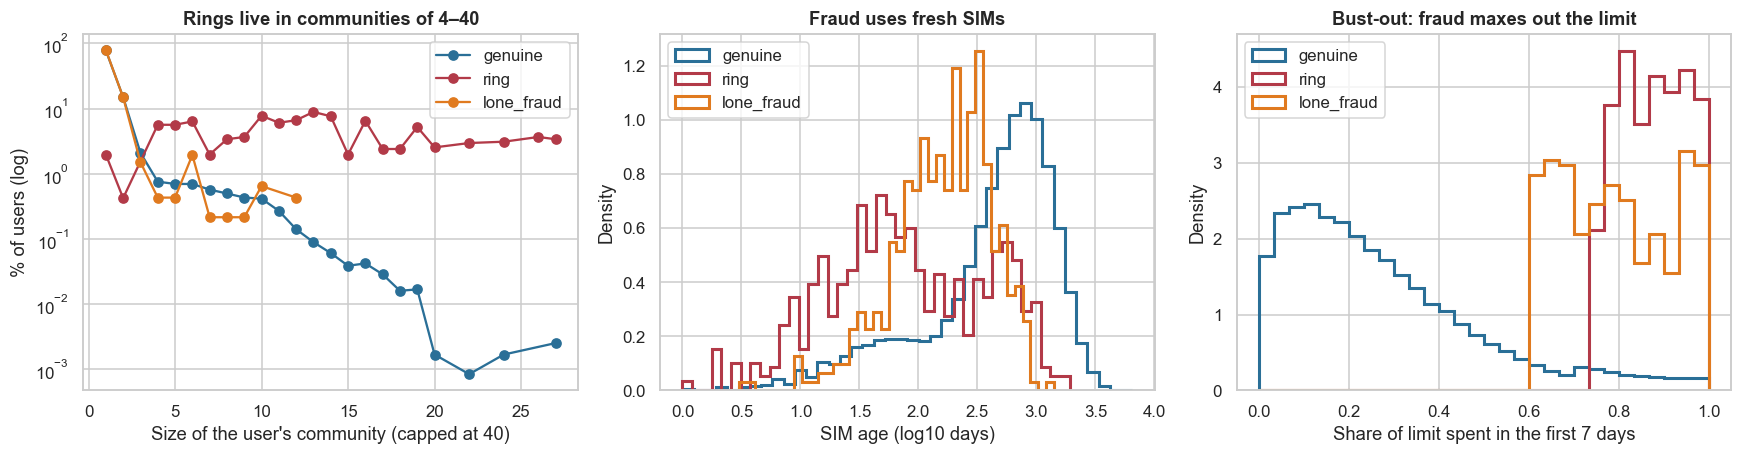

In [6]:
lab10, size10 = static_components(df, 10)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for k, c_ in (("genuine", "#2a6f97"), ("ring", "#b23a48"), ("lone_fraud", "#e07a1f")):
    m = (df._kind == k).values; vals, cnt = np.unique(np.clip(size10[m], 1, 40), return_counts=True)
    axes[0].plot(vals, cnt / m.sum() * 100, "o-", color=c_, label=k)
axes[0].set_yscale("log"); axes[0].set_xlabel("Size of the user's community (capped at 40)"); axes[0].set_ylabel("% of users (log)"); axes[0].set_title("Rings live in communities of 4–40"); axes[0].legend()
for k, c_ in (("genuine", "#2a6f97"), ("ring", "#b23a48"), ("lone_fraud", "#e07a1f")):
    axes[1].hist(np.log10(df.sim_age_days[df._kind == k] + 1), bins=40, density=True, histtype="step", lw=2, color=c_, label=k)
axes[1].set_xlabel("SIM age (log10 days)"); axes[1].set_ylabel("Density"); axes[1].set_title("Fraud uses fresh SIMs"); axes[1].legend()
util = df.spend_first7d_inr / df.credit_limit_inr
for k, c_ in (("genuine", "#2a6f97"), ("ring", "#b23a48"), ("lone_fraud", "#e07a1f")):
    axes[2].hist(util[df._kind == k], bins=30, range=(0, 1), density=True, histtype="step", lw=2, color=c_, label=k)
axes[2].set_xlabel("Share of limit spent in the first 7 days"); axes[2].set_ylabel("Density"); axes[2].set_title("Bust-out: fraud maxes out the limit"); axes[2].legend()
plt.tight_layout(); plt.show()

**Takeaway:** - **Left:** genuine users mostly sit alone or in small family groups (size 1–3); ring members sit in communities of **4–27**. Size alone is not enough, since some genuine hostel and family groups are that big too.
- **Middle:** fraud uses newer SIMs, but 15% of genuine users also have new numbers, so SIM age is a weak signal on its own.
- **Right:** the bust-out signature: ring members spend **75–100% of their limit in the first week**, while genuine users typically spend 10–40%. That signal arrives too late to stop the first loss. It is useful for limits and collections, not onboarding.

## 7. Statistical Analysis (core section)

### 7.1 Do defaults cluster in communities more than chance? (permutation test)

**(a) Why?** Before building graph features, we check that the graph carries signal. **Statistic:** among FPD users in communities of size ≥ 2, the share whose community contains **another** FPD user. **Null distribution:** shuffle FPD labels across all users 500 times (keeping the graph fixed). **(b) Assumption:** exchangeability of labels under H0. We use the pruned graph (attribute nodes shared by ≤ 10 users; 7.2 justifies the choice).

In [7]:
def co_default_share(lab, size, y):
    m = size >= 2; comp_fpd = pd.Series(y[m]).groupby(lab[m]).transform("sum").values
    return ((comp_fpd >= 2) & (y[m] == 1)).sum() / max((y[m] == 1).sum(), 1)
y_fpd = df.fpd.values; obs = co_default_share(lab10, size10, y_fpd)
null = np.array([co_default_share(lab10, size10, RNG.permutation(y_fpd)) for _ in range(500)])
p_perm = (1 + (null >= obs).sum()) / (1 + len(null))
obs_g = co_default_share(lab10, size10, ((df.fpd == 1) & (df.fraud == 0)).astype(int).values)
print(f"FPD users in shared communities whose community has another FPD: observed {obs:.1%} vs permutation mean {null.mean():.1%} (95th pct {np.percentile(null, 95):.1%}); p = {p_perm:.4f}")
print(f"Same statistic for genuine credit-stress defaults only: {obs_g:.1%} (fraud drives the clustering)")

FPD users in shared communities whose community has another FPD: observed 45.2% vs permutation mean 9.1% (95th pct 11.1%); p = 0.0020
Same statistic for genuine credit-stress defaults only: 4.3% (fraud drives the clustering)


**(c)/(f) Observation:** among defaulters who share a community with someone, **45.2%** have another defaulter in the same community, vs **9.1%** when default labels are shuffled at random (95th percentile 11.1%; permutation p = 0.002, the minimum possible with 500 shuffles). For **genuine credit-stress defaults alone** the figure is only 4.3%, *below* chance. **(f) Business meaning:** the graph carries real signal, and it is fraud signal. Ordinary repayment trouble does not cluster, so community features will not penalise genuine customers just for knowing someone who struggles to repay.

### 7.2 Building the graph without punishing good users: hub-pruning sensitivity

**(a) Why?** An address shared by 60 people is a hostel, not a gang. We drop **attribute nodes shared by more than D users** before forming communities, and measure for each D:
- **Ring coverage:** the share of ring members placed in a community of ≥ 4 users.
- **Collateral damage:** the share of genuine users placed in such communities.
- **Ring purity:** the share of ring members' community-mates who are also fraud.

Wilson CIs for the shares.

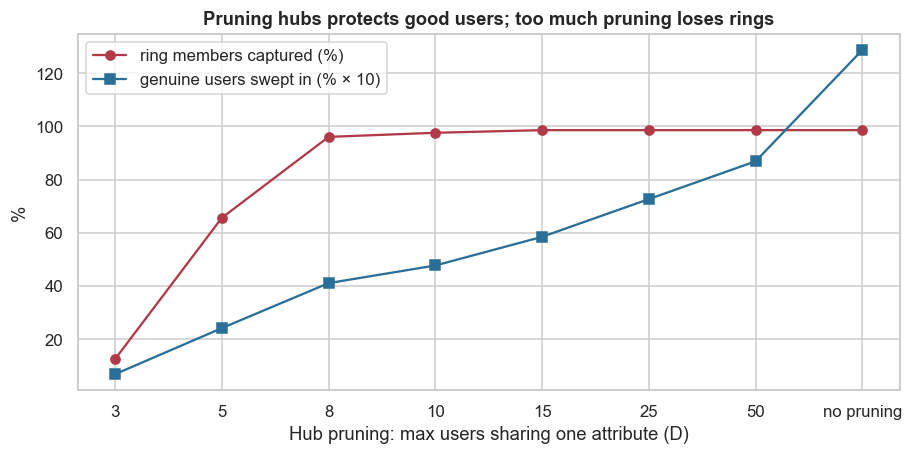

,ring members in community ≥ 4,genuine users in community ≥ 4,CI low,CI high,genuine users affected,ring purity,largest community
max users per attribute (D),,,,,,,
3,0.1254,0.0069,0.0064,0.0073,815,0.9663,9
5,0.6563,0.0242,0.0233,0.0251,2872,0.9696,18
8,0.9606,0.0411,0.0400,0.0422,4882,0.9623,24
10,0.9761,0.0477,0.0465,0.0489,5670,0.9616,27
15,0.9859,0.0585,0.0572,0.0598,6950,0.9580,35
25,0.9859,0.0727,0.0712,0.0742,8635,0.9446,45
50,0.9859,0.0869,0.0853,0.0885,10324,0.9446,78
no pruning,0.9859,0.1287,0.1268,0.1306,15296,0.9412,2394


In [8]:
hp = []; ring = (df._kind == "ring").values; gen_ = (df.fraud == 0).values
for D in (3, 5, 8, 10, 15, 25, 50, 10 ** 9):
    lab, size = static_components(df, D); big = size >= 4
    comp_f = pd.Series(df.fraud.values).groupby(lab).transform("sum").values
    purity = ((comp_f[ring] - 1) / np.maximum(size[ring] - 1, 1))[big[ring]].mean()
    g_lo, g_hi = proportion_confint(big[gen_].sum(), gen_.sum(), method="wilson")
    hp.append(("no pruning" if D > 10 ** 6 else D, big[ring].mean(), big[gen_].mean(), g_lo, g_hi, int(big[gen_].sum()), purity, int(size.max())))
hp = pd.DataFrame(hp, columns=["max users per attribute (D)", "ring members in community ≥ 4", "genuine users in community ≥ 4", "CI low", "CI high", "genuine users affected", "ring purity", "largest community"]).set_index("max users per attribute (D)")
fig, ax = plt.subplots(figsize=(8.5, 4.3))
xs = np.arange(len(hp)); ax.plot(xs, hp.iloc[:, 0] * 100, "o-", color="#b23a48", label="ring members captured (%)")
ax.plot(xs, hp.iloc[:, 1] * 100 * 10, "s-", color="#2a6f97", label="genuine users swept in (% × 10)")
ax.set_xticks(xs); ax.set_xticklabels(hp.index.astype(str)); ax.set_xlabel("Hub pruning: max users sharing one attribute (D)"); ax.set_ylabel("%")
ax.set_title("Pruning hubs protects good users; too much pruning loses rings"); ax.legend(); plt.tight_layout(); plt.show()
hp.round(4)

**Takeaway:** - **Without pruning**, 98.6% of ring members are in communities of 4+, but so are **12.9% of genuine users (15,296 people)**, and the largest "community" has 2,394 members.
- **Dropping attributes shared by more than 10 users** keeps **97.6%** of ring members and cuts collateral to **4.8%** (5,670 genuine users; CI 4.65–4.89%). The largest community shrinks to 27.
- **Pruning harder (D ≤ 5)** starts losing rings: only 66% are captured at D = 5 and 13% at D = 3, because gangs re-use one device or address across 5–10 accounts.
- Ring purity (the share of a ring member's community-mates who are also fraud) stays at 94–97%.

**(f) Business meaning:** pruning is the single most important design choice. D ≈ 8–10 is the sweet spot here; in production, tune D on investigated cases.

### 7.3 Building features as of onboarding time: nightly batch vs real time

Graph features must use only users who onboarded **before** the applicant. We compute them two ways:
- **Nightly batch** (Airflow-style): the graph as of midnight. Same-day ring members cannot see each other.
- **Real time** (Flink-style): the graph updated **hourly**.

For each applicant, we look up the communities its device, address, bank account and email pattern belong to (attributes shared by ≤ 10 earlier users) and add up community size, recent sign-ups (last 14 days), fresh-SIM members and **already-known defaulters** (FPD becomes known 45 days after onboarding).

In [9]:
DPRUNE = 10; t0 = time.time()
codes = {a: pd.factorize(df[a])[0] for a in ATTR}                                 # -1 = missing
offs = np.cumsum([0] + [codes[a].max() + 1 for a in ATTR]); N_U = len(df); N_NODE = N_U + offs[-1]
anode = {a: np.where(codes[a] >= 0, N_U + offs[i] + codes[a], -1) for i, a in enumerate(ATTR)}
fresh = (df.sim_age_days < 60).values; fpd_known_day = df.day.values + 45
def graph_features(bin_days):
    b = np.floor(df.day.values / bin_days).astype(int); out = np.zeros((N_U, 8))
    for bb in np.unique(b):
        past = np.flatnonzero(b < bb); cur = np.flatnonzero(b == bb); t_now = bb * bin_days
        deg = np.zeros(N_NODE, int)
        for a in ATTR:
            v = anode[a][past]; deg += np.bincount(v[v >= 0], minlength=N_NODE)
        for j, a in enumerate(ATTR):                                               # direct (1-hop) sharing counts, unpruned
            v = anode[a][cur]; out[cur, j] = np.where(v >= 0, deg[np.maximum(v, 0)], 0)
        if len(past) == 0: continue
        r, c = [], []
        for a in ATTR:
            v = anode[a][past]; keep = (v >= 0) & (deg[np.maximum(v, 0)] + 1 <= DPRUNE); r.append(past[keep]); c.append(v[keep])
        r, c = np.concatenate(r), np.concatenate(c)
        _, lab = connected_components(coo_matrix((np.ones(len(r)), (r, c)), shape=(N_NODE, N_NODE)), directed=False)
        lp = lab[past]; ncomp = lab.max() + 1
        agg = np.vstack([np.bincount(lp, minlength=ncomp), np.bincount(lp, weights=(df.day.values[past] > t_now - 14).astype(float), minlength=ncomp),
                         np.bincount(lp, weights=fresh[past].astype(float), minlength=ncomp),
                         np.bincount(lp, weights=((y_fpd[past] == 1) & (fpd_known_day[past] < t_now)).astype(float), minlength=ncomp)])
        C = np.full((len(ATTR), len(cur)), -1)
        for j, a in enumerate(ATTR):
            v = anode[a][cur]; ok = (v >= 0) & (deg[np.maximum(v, 0)] >= 1) & (deg[np.maximum(v, 0)] + 1 <= DPRUNE)
            C[j, ok] = lab[v[ok]]
        for j in range(1, len(ATTR)):                                               # count each community once per applicant
            for i in range(j): C[j, C[j] == C[i]] = -1
        tot = np.zeros((4, len(cur)))
        for j in range(len(ATTR)):
            ok = C[j] >= 0; tot[:, ok] += agg[:, C[j, ok]]
        out[cur, 4:] = tot.T
    return pd.DataFrame(out, columns=["deg_device", "deg_address", "deg_bank", "deg_email", "comm_size", "comm_recent", "comm_fresh_sim", "comm_known_fpd"], index=df.index)
G_batch = graph_features(1.0); G_rt = graph_features(1 / 24)
print(f"Graph features built in {time.time() - t0:.0f}s (nightly batch: 91 snapshots; real time: 2,184 hourly snapshots)")
G_rt.assign(kind=df._kind).groupby("kind").mean().round(2)

Graph features built in 342s (nightly batch: 91 snapshots; real time: 2,184 hourly snapshots)


,deg_device,deg_address,deg_bank,deg_email,comm_size,comm_recent,comm_fresh_sim,comm_known_fpd
kind,,,,,,,,
genuine,0.0300,6.1800,0.0200,0.0000,0.2800,0.1300,0.0300,0.0000
lone_fraud,0.0300,5.1500,0.0200,0.0000,0.3200,0.1000,0.0400,0.0000
ring,1.8000,1.4300,2.4500,2.3500,6.0500,5.9700,2.6600,0.0000


**Observation:** building features from the graph *as it existed when each applicant signed up* took 342 seconds for 2,184 hourly snapshots. Ring members arrive already linked to **≈ 6 earlier users** (sharing a device with 1.8, a bank account with 2.5, an email pattern with 2.4 on average), vs ≈ 0.3 for genuine users. Genuine users' links are mostly **addresses** (6.2: hostels and PGs below the pruning cut-off). **"Known defaulters in the community" is always ≈ 0:** FPD becomes known only ~45 days after onboarding, long after the ring has finished. Waiting for defaults is not a fraud defence.

### 7.4 What does each layer of information add? Individual → 1-hop links → communities → first-week behaviour

**(a) Why?** Each layer costs engineering: 1-hop counts need a lookup table, communities need a graph store, behaviour needs waiting a week. We train the same gradient-boosting model on cumulative feature tiers (training users: weeks 1–7, label = FPD as the lender would) and score test users (weeks 9–13). Evaluation is against **true fraud** with DeLong for adjacent tiers (Holm). Recall at a **1% decline budget** is the business metric.
**(b)** Tiers 1–3 are available **at onboarding**; tier 4 only after 7 days (useful for limit decisions and collections, too late to stop a bust-out).

In [10]:
df["util7"] = df.spend_first7d_inr / df.credit_limit_inr; df["hour"] = df.onboard_ts.dt.hour
IND = ["sim_age_days", "credit_limit_inr", "hour"]; HOP = ["deg_device", "deg_address", "deg_bank", "deg_email"]; COM = ["comm_size", "comm_recent", "comm_fresh_sim", "comm_known_fpd"]
BEH = ["util7", "n_txn_first7d", "n_merchants_first7d", "night_txn_first7d"]
X = pd.concat([df[IND + BEH], G_rt], axis=1); Xb = pd.concat([df[IND + BEH], G_batch], axis=1)
TR = (df.day < 49).values; TE = (df.day >= 56).values; yf_te = df.fraud.values[TE]; K1 = int(0.01 * TE.sum())
def hgb(): return HGB(max_iter=300, learning_rate=0.06, max_leaf_nodes=31, random_state=SEED)
def delong(y, preds):
    y = np.asarray(y); pos, neg = preds[:, y == 1], preds[:, y == 0]; m, n = pos.shape[1], neg.shape[1]
    tx = np.array([rankdata(p) for p in pos]); ty = np.array([rankdata(q) for q in neg]); tz = np.array([rankdata(np.r_[p, q]) for p, q in zip(pos, neg)])
    aucs = tz[:, :m].sum(1) / m / n - (m + 1) / 2 / n; v01 = (tz[:, :m] - tx) / n; v10 = 1 - (tz[:, m:] - ty) / m
    return aucs, np.atleast_2d(np.cov(v01)) / m + np.atleast_2d(np.cov(v10)) / n
def rec_at(p, y=yf_te, k=K1): return y[np.argsort(-p)[:k]].sum() / y.sum()
TIERS = {"1 individual (SIM age, limit, hour)": IND, "2 + 1-hop sharing counts": IND + HOP, "3 + graph communities": IND + HOP + COM, "4 + first-week behaviour (day 7)": IND + HOP + COM + BEH}
P = {}
for nm, f in TIERS.items(): P[nm] = hgb().fit(X.loc[TR, f], df.fpd[TR]).predict_proba(X.loc[TE, f])[:, 1]
names = list(P); A_, C_ = delong(yf_te, np.vstack([P[n] for n in names]))
tier = pd.DataFrame({"AUC vs true fraud": A_, "PR-AUC": [average_precision_score(yf_te, P[n]) for n in names], "recall @1% declines": [rec_at(P[n]) for n in names],
                     "ring recall @1%": [df._kind.values[TE][np.argsort(-P[n])[:K1]].tolist().count("ring") / (df._kind.values[TE] == "ring").sum() for n in names],
                     "AUC vs FPD (lender's view)": [roc_auc_score(df.fpd.values[TE], P[n]) for n in names]}, index=names)
pv = [2 * stats.norm.sf(abs(A_[i + 1] - A_[i]) / np.sqrt(C_[i, i] + C_[i + 1, i + 1] - 2 * C_[i, i + 1])) for i in range(len(names) - 1)]
tier["Δ AUC vs previous tier"] = np.r_[np.nan, np.diff(A_)]; tier["DeLong p (vs previous)"] = np.r_[np.nan, pv]; tier["p_holm"] = np.r_[np.nan, multipletests(pv, method="holm")[1]]
print(f"Test: {TE.sum():,} applicants, {yf_te.sum()} fraudsters ({(df._kind.values[TE] == 'ring').sum()} ring members); decline budget = {K1} (1%)")
tier.round(4)

Test: 46,276 applicants, 475 fraudsters (287 ring members); decline budget = 462 (1%)


,AUC vs true fraud,PR-AUC,recall @1% declines,ring recall @1%,AUC vs FPD (lender's view),Δ AUC vs previous tier,DeLong p (vs previous),p_holm
"1 individual (SIM age, limit, hour)",0.7340,0.0250,0.0211,0.0279,0.5565,NaN,NaN,NaN
2 + 1-hop sharing counts,0.8323,0.5317,0.5137,0.8397,0.5865,0.0983,0.0000,0.0000
3 + graph communities,0.8408,0.5364,0.5137,0.8432,0.5909,0.0085,0.1923,0.1923
4 + first-week behaviour (day 7),0.9908,0.8053,0.7242,0.9477,0.6163,0.1501,0.0000,0.0000


**(c)/(f) Observation:** - **Individual features alone** (SIM age, limit, onboarding hour) are nearly useless at the decision point: AUC 0.73, but **recall at 1% only 2%**. Trained on FPD, this model mostly picks up credit stress.
- **Adding 1-hop sharing counts** is the big step: AUC **0.83** (+0.098, Holm p < 0.0001), recall **51%**, ring recall **84%**.
- **Multi-hop communities add little more:** AUC +0.009 (Holm p = 0.19), same recall. The direct link counts already carry most of the ring signal.
- **First-week behaviour** jumps AUC to 0.99 and recall to 72%, but it is available only on day 7, after the money is gone.
- **(f) Business meaning:** the essential investment is a **real-time identity-link lookup** (how many earlier users share this attribute). A full graph engine is useful for investigation and ring take-downs, but adds little to the onboarding decision here.

### 7.5 Nightly batch vs real-time graph updates

Same tier-3 model (available at onboarding); features from the nightly graph vs the hourly graph. Paired comparison of the frauds caught at a 1% decline budget (exact McNemar), split by whether the applicant had a ring-mate who signed up **earlier the same day**.

In [11]:
f3 = TIERS["3 + graph communities"]
p_rt = P["3 + graph communities"]; p_bt = hgb().fit(Xb.loc[TR, f3], df.fpd[TR]).predict_proba(Xb.loc[TE, f3])[:, 1]
top_rt = np.zeros(TE.sum(), bool); top_rt[np.argsort(-p_rt)[:K1]] = True; top_bt = np.zeros(TE.sum(), bool); top_bt[np.argsort(-p_bt)[:K1]] = True
fr = yf_te == 1
mt = mcnemar([[int((top_rt & top_bt & fr).sum()), int((top_rt & ~top_bt & fr).sum())], [int((~top_rt & top_bt & fr).sum()), int((~top_rt & ~top_bt & fr).sum())]], exact=True)
dte = df[TE]; same_day = dte.groupby(["_ring", np.floor(dte.day)]).cumcount().values > 0; same_day &= (dte._kind == "ring").values
print(f"Fraud recall @1%: real time {top_rt[fr].mean():.1%} vs nightly batch {top_bt[fr].mean():.1%}; caught only by real time {int((top_rt & ~top_bt & fr).sum())}, "
      f"only by batch {int((~top_rt & top_bt & fr).sum())}; exact McNemar p = {mt.pvalue:.3g}")
print(f"Ring members with an earlier same-day ring-mate: {same_day.sum()} — recall real time {top_rt[same_day].mean():.1%} vs batch {top_bt[same_day].mean():.1%}")
print(f"AUC real time {roc_auc_score(yf_te, p_rt):.4f} vs batch {roc_auc_score(yf_te, p_bt):.4f}")

Fraud recall @1%: real time 51.4% vs nightly batch 50.3%; caught only by real time 12, only by batch 7; exact McNemar p = 0.359
Ring members with an earlier same-day ring-mate: 115 — recall real time 90.4% vs batch 83.5%
AUC real time 0.8408 vs batch 0.8320


**Observation:** the hourly-updated graph catches **51.4%** of frauds vs **50.3%** for the nightly batch. 12 frauds are caught only in real time and 7 only by the batch (exact McNemar p = 0.36), so there is no significant overall difference. The gap shows up where expected: for the **115 ring members whose ring-mate signed up earlier the same day**, real time catches **90.4% vs 83.5%**. **Business meaning:** real-time link updates matter for fast "burst" rings. Since rings mostly sign up over days, a nightly graph plus real-time 1-hop counters (cheap to keep current) is a sensible architecture under the documented 70–80 ms SLA.

### 7.6 Which label should the model learn? FPD vs confirmed fraud

The lender observes **first-payment default**, and only about a quarter of FPDs are fraud (the rest are genuine credit stress). A fraud team can build a cleaner label by investigating defaulters. We compare a tier-3 model trained on FPD with one trained on **confirmed fraud**, which in practice requires investigation, simulated here by the hidden truth.

In [12]:
p_fr = hgb().fit(X.loc[TR, f3], df.fraud[TR]).predict_proba(X.loc[TE, f3])[:, 1]
lab_t = pd.DataFrame({"trained on FPD": [roc_auc_score(yf_te, p_rt), rec_at(p_rt), df.fraud.values[TE][np.argsort(-p_rt)[:K1]].mean(), df.fpd.values[TE][np.argsort(-p_rt)[:K1]].mean()],
                      "trained on confirmed fraud": [roc_auc_score(yf_te, p_fr), rec_at(p_fr), df.fraud.values[TE][np.argsort(-p_fr)[:K1]].mean(), df.fpd.values[TE][np.argsort(-p_fr)[:K1]].mean()]},
                     index=["AUC vs true fraud", "fraud recall @1%", "precision (fraud) of declines", "share of declines that default (FPD)"])
a2, c2 = delong(yf_te, np.vstack([p_rt, p_fr])); print(f"DeLong (confirmed-fraud vs FPD label): ΔAUC = {a2[1] - a2[0]:+.4f}, p = {2 * stats.norm.sf(abs(a2[1] - a2[0]) / np.sqrt(c2[0, 0] + c2[1, 1] - 2 * c2[0, 1])):.2g}")
lab_t.round(4)

DeLong (confirmed-fraud vs FPD label): ΔAUC = +0.0478, p = 3e-09


,trained on FPD,trained on confirmed fraud
AUC vs true fraud,0.8408,0.8886
fraud recall @1%,0.5137,0.5284
precision (fraud) of declines,0.5281,0.5433
share of declines that default (FPD),0.5173,0.5325


**Observation:** training on **confirmed fraud** instead of FPD raises AUC from 0.841 to **0.889** (+0.048, DeLong p ≈ 3e-9) and recall at 1% from 51.4% to 52.8%. FPD-trained models waste capacity learning genuine credit stress (78% of FPDs). **Business meaning:** a small investigation step that tags each early defaulter as "fraud" or "credit stress" pays off. It gives the fraud model a cleaner target, and gives the credit model the right one.

### 7.7 Precision of declines, counted honestly: cluster bootstrap by community

Declines are **clustered**: if one ring member is declined, its ring-mates often are too. A naive binomial CI treats declines as independent and is too narrow. We bootstrap **communities** (resampling whole connected groups, as of the end of the period) to get a cluster-robust CI for the precision of the 1% decline list.

In [13]:
p_use = p_rt; top = np.argsort(-p_use)[:K1]; dec = df.index[TE][top]
comm_id = lab10[dec]; hit = df.fraud.values[dec]
g = pd.DataFrame({"c": comm_id, "h": hit}).groupby("c").h.agg(["sum", "size"])
bs = []
for _ in range(2000):
    s_ = g.iloc[RNG.integers(0, len(g), len(g))]; bs.append(s_["sum"].sum() / s_["size"].sum())
lo_n, hi_n = proportion_confint(hit.sum(), len(hit), method="wilson")
print(f"Precision of the {K1} declines: {hit.mean():.1%} | naive Wilson CI {lo_n:.1%}–{hi_n:.1%} | cluster-bootstrap CI {np.percentile(bs, 2.5):.1%}–{np.percentile(bs, 97.5):.1%} "
      f"({len(g)} distinct communities; largest contributes {g['size'].max()} declines)")
print(f"Good users declined per fraudster stopped: {(1 - hit).sum() / hit.sum():.2f}")

Precision of the 462 declines: 52.8% | naive Wilson CI 48.3%–57.3% | cluster-bootstrap CI 38.6%–62.4% (240 distinct communities; largest contributes 22 declines)
Good users declined per fraudster stopped: 0.89


**Observation:** - **Precision:** of the 462 declines (1% budget), **52.8%** are fraudsters. The naive binomial CI (48–57%) is **too narrow**. Resampling whole communities gives **38.6–62.4%**, because declines come in correlated clusters (240 communities, one contributing 22 declines). Precision claims about graph-based rules need cluster-robust intervals.
- **Cost to good users:** at this budget, **0.89 good (non-defaulting) users are declined per fraudster stopped**. The next section shows that the 1% budget is past the optimum.

### 7.8 Where to draw the decline line: total cost including good users

**Cost model (D-10-06), per test applicant:**
- **Approve a fraudster:** lose 90% of the limit (bust-out).
- **Approve a genuine user who will default for credit reasons:** lose 50% of the limit.
- **Decline a good user:** lose their 12-month margin, ₹1,200 (interchange-style merchant fees on repeat purchases).
- **Approve a good user:** that margin is earned (counted as zero cost here).

We sweep the decline share and report frauds stopped, good users lost and net ₹.

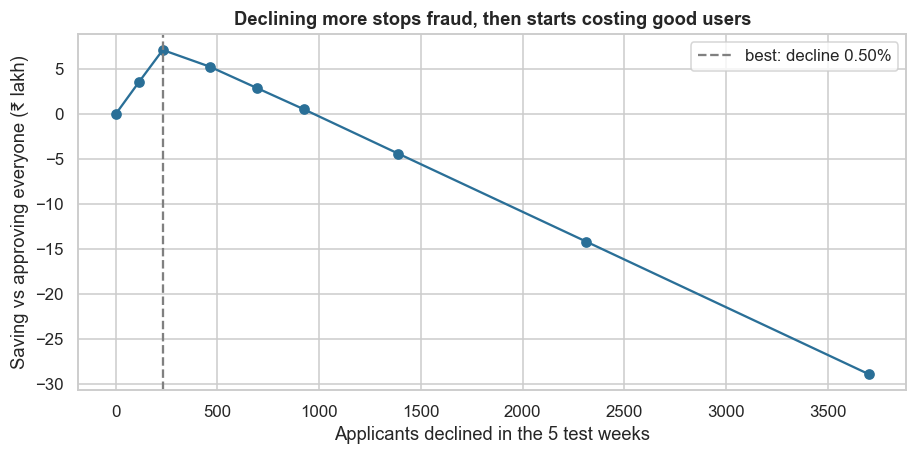

,declines,fraud recall,good users declined,total cost ₹ lakh,saving vs approve-all ₹ lakh
decline share,,,,,
0.00%,0,0.0000,0,39.3860,0.0000
0.25%,115,0.2420,0,35.8040,3.5820
0.50%,231,0.4840,1,32.2750,7.1120
1.00%,462,0.5140,211,34.1280,5.2580
1.50%,694,0.5180,432,36.5020,2.8840
2.00%,925,0.5200,649,38.8660,0.5200
3.00%,1388,0.5350,1099,43.7840,-4.3980
5.00%,2313,0.5580,1984,53.5680,-14.1820
8.00%,3702,0.5980,3315,68.2970,-28.9110


In [14]:
LTV = 1200
lim = df.credit_limit_inr.values[TE]; kind = df._kind.values[TE]; fpd_te = df.fpd.values[TE]
loss_if_approved = np.where(kind != "genuine", 0.9 * lim, np.where(fpd_te == 1, 0.5 * lim, 0.0)); cost_if_declined = np.where((kind == "genuine") & (fpd_te == 0), LTV, 0.0)
order = np.argsort(-p_rt); base = loss_if_approved.sum(); rows = []
for share in (0, 0.0025, 0.005, 0.01, 0.015, 0.02, 0.03, 0.05, 0.08):
    k = int(share * len(order)); d = np.zeros(len(order), bool); d[order[:k]] = True
    cost = loss_if_approved[~d].sum() + cost_if_declined[d].sum()
    rows.append((f"{share:.2%}", k, (d & (kind != "genuine")).sum() / (kind != "genuine").sum(), int((d & (kind == "genuine") & (fpd_te == 0)).sum()), cost / 1e5, (base - cost) / 1e5))
cc = pd.DataFrame(rows, columns=["decline share", "declines", "fraud recall", "good users declined", "total cost ₹ lakh", "saving vs approve-all ₹ lakh"]).set_index("decline share")
best = cc["total cost ₹ lakh"].idxmin()
fig, ax = plt.subplots(figsize=(8.5, 4.3))
ax.plot(cc["declines"], cc["saving vs approve-all ₹ lakh"], "o-", color="#2a6f97"); ax.axvline(cc.loc[best, "declines"], ls="--", color="grey", label=f"best: decline {best}")
ax.set_xlabel("Applicants declined in the 5 test weeks"); ax.set_ylabel("Saving vs approving everyone (₹ lakh)"); ax.set_title("Declining more stops fraud, then starts costing good users"); ax.legend()
plt.tight_layout(); plt.show()
cc.round(3)

**Takeaway:** - **Total cost is lowest at a 0.5% decline share:** a saving of **₹7.1 lakh over the 5 test weeks**. That stops **48% of fraudsters** and declines just **1 good user**: the very top of the score is almost pure fraud.
- **Beyond the optimum,** more fraud is caught but good users are lost fast: 211 at 1%, 649 at 2%. Above ≈ 2.5% the policy **costs more than approving everyone**.
- **(f) Business meaning:** the documented "impact on good users" is the deciding factor. The optimal line is narrow (0.25–1%), and above it each extra fraudster stopped costs several good customers.

## 8. ML Section — gradient boosting vs a small neural network

Simpl describes moving from rules to ML to **neural networks**. As a short check (no tuning), we train a small multi-layer perceptron (2 hidden layers, 64-32, early stopping) on the same tier-3 features (log-scaled, standardised) and compare it with gradient boosting.

In [15]:
Xl = np.log1p(X[f3].clip(lower=0))
mlp = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(64, 32), early_stopping=True, max_iter=300, random_state=SEED)).fit(Xl[TR], df.fpd[TR])
p_mlp = mlp.predict_proba(Xl[TE])[:, 1]; a3, c3 = delong(yf_te, np.vstack([p_rt, p_mlp]))
print(f"AUC vs true fraud: gradient boosting {a3[0]:.4f} vs MLP {a3[1]:.4f} (DeLong p = {2 * stats.norm.sf(abs(a3[1] - a3[0]) / np.sqrt(c3[0, 0] + c3[1, 1] - 2 * c3[0, 1])):.2g}); "
      f"recall @1%: {rec_at(p_rt):.1%} vs {rec_at(p_mlp):.1%}")
imp = pd.Series({f: roc_auc_score(yf_te, X.loc[TE, f]) for f in f3}).sort_values(ascending=False)
print("Single-feature AUC vs true fraud (direction-free):"); print(imp.apply(lambda a: max(a, 1 - a)).round(3).to_string())

AUC vs true fraud: gradient boosting 0.8408 vs MLP 0.8321 (DeLong p = 0.36); recall @1%: 51.4% vs 49.9%


Single-feature AUC vs true fraud (direction-free):
comm_recent        0.7700
comm_size          0.7650
comm_fresh_sim     0.7310
deg_bank           0.6770
deg_device         0.6770
deg_email          0.6590
deg_address        0.6120
hour               0.5260
credit_limit_inr   0.5000
comm_known_fpd     0.5020
sim_age_days       0.7810


**Observation:** the small neural network (AUC 0.832) is **not better** than gradient boosting (0.841; DeLong p = 0.36) on these tabular link features, and recall at 1% is similar (49.9% vs 51.4%). Simpl's move to neural networks makes sense when combining the raw transaction payload with long histories (sequence data). For a dozen engineered link counts, boosting is simpler and equally good. **Single-feature AUCs** confirm the graph signal: **recent community sign-ups (0.77)**, community size (0.77), fresh-SIM members (0.73) and shared bank account / device (0.68). Every one of these is weak alone; together with SIM age they make the model.

## 9. Business Translation — ₹ impact at scale

In [16]:
weeks_test = (df.day[TE].max() - 56) / 7; SCALE_USERS_MONTH = 5e5                      # assumption: 5 lakh new users a month (D-10-07)
per_user = lambda lakh: lakh * 1e5 / TE.sum()
sc = pd.DataFrame({"saving per applicant ₹": [per_user(cc.loc[s, "saving vs approve-all ₹ lakh"]) for s in cc.index],
                   "₹ crore / month at 5 lakh sign-ups": [per_user(cc.loc[s, "saving vs approve-all ₹ lakh"]) * SCALE_USERS_MONTH / 1e7 for s in cc.index],
                   "good users declined / month": [cc.loc[s, "good users declined"] / TE.sum() * SCALE_USERS_MONTH for s in cc.index]}, index=cc.index)
tiers_money = {}
for nm in names[:3]:
    d = np.zeros(TE.sum(), bool); d[np.argsort(-P[nm])[:int(0.01 * TE.sum())]] = True
    tiers_money[nm] = per_user((base - (loss_if_approved[~d].sum() + cost_if_declined[d].sum())) / 1e5) * SCALE_USERS_MONTH / 1e7
print("Saving at a 1% decline budget by onboarding feature tier (₹ crore / month):"); print(pd.Series(tiers_money).round(2).to_string())
sc.round(2)

Saving at a 1% decline budget by onboarding feature tier (₹ crore / month):
1 individual (SIM age, limit, hour)   -0.4900
2 + 1-hop sharing counts               0.5800
3 + graph communities                  0.5700


,saving per applicant ₹,₹ crore / month at 5 lakh sign-ups,good users declined / month
decline share,,,
0.00%,0.0000,0.0000,0.0000
0.25%,7.7400,0.3900,0.0000
0.50%,15.3700,0.7700,10.8000
1.00%,11.3600,0.5700,"2,279.8000"
1.50%,6.2300,0.3100,"4,667.6500"
2.00%,1.1200,0.0600,"7,012.2700"
3.00%,-9.5000,-0.4800,"11,874.4100"
5.00%,-30.6500,-1.5300,"21,436.6000"
8.00%,-62.4800,-3.1200,"35,817.7000"


**Takeaway (business reading):** at an assumed **5 lakh new users per month**:
- **At the optimal 0.5% decline share:** the model saves ≈ **₹0.77 crore/month** (₹15.4 per applicant) and declines ≈ **11 good users a month**.
- **At a 1% budget:** saving ≈ ₹0.57 crore/month, but ≈ **2,300 good users declined a month**.
- **At 2%:** almost no saving left, and ≈ 7,000 good users lost.
- **By feature tier at 1%:** individual features alone lose money (−₹0.49 crore/month, from declining credit-stress profiles instead of fraud); with 1-hop link counts the saving is ≈ +₹0.58 crore/month; full communities add nothing in ₹.
- **Reading:** the ₹ value comes from **link counts plus a tight decline budget**. The figures depend on the assumed ₹1,200 good-user lifetime value and fraud loss of 90% of limit.

## 10. Recommendation and Decision

**Decision against the hypotheses:**
- **H1 ✅:** defaults cluster (fraud-driven).
- **H2:** 1-hop links add a lot ✅; communities add no significant AUC beyond 1-hop ❌.
- **H3 ❌:** real-time vs batch is not significant overall (only for same-day ring-mates).
- **H4:** the confirmed-fraud label is better (+0.05 AUC).
- **Guardrail met:** at the 0.5% budget, about 1 good user is declined per 230 declines.

**I recommend:**
1. **Onboarding gate:** score every applicant with SIM age + **hub-pruned 1-hop sharing counts** (device, address, bank account, email pattern), updated in real time. **Decline or give a ₹500 starter limit to the top 0.5%**, then review the band 0.5–1% manually.
2. **Hub pruning and data hygiene:** exclude attributes shared by more than ~10 users and all placeholder or default IDs. Re-tune the cut-off quarterly on investigated cases.
3. **Communities as an investigation tool:** run nightly community detection to take down whole rings (block all members) and feed investigators, rather than as a model input.
4. **Labels:** tag every early defaulter as fraud or credit stress, and train the fraud model on fraud.
5. **Day-7 review:** use first-week behaviour (limit spent within days, many merchants) to freeze limits on new accounts that look like bust-outs. It catches 72% at 1%.
6. **Fairness guardrail:** monitor decline rates for users in shared-address (hostel/PG/family) communities vs others.

**KPIs:** fraud loss per ₹100 disbursed; good users declined per fraudster stopped; share of genuine users in communities of 4+; fraud recall at the decline budget on matured labels; ring take-downs per month; decline-rate gap for shared-address users.

## 11. Risks, Limitations and Next Steps

- **Synthetic rings:** real gangs adapt, using fresh devices per account and rented addresses. Graph value decays as rings learn, which is why the 1-hop and community features must be refreshed with new link types (UPI handles, employer IDs, KYC document hashes).
- **Collateral damage is a fairness issue:** hostels, PGs and joint families are often students and lower-income users. Monitor decline rates for users in shared-address communities, and offer a **lower limit or extra verification** instead of a flat decline.
- **Label delay:** FPD is known only ~45 days after onboarding, so "known defaulters" in a community lag behind the ring. Investigator-confirmed fraud flags shorten this.
- **Privacy:** linking identities is processing personal data. It needs a lawful purpose (fraud prevention is a legitimate use under the DPDP Act), data minimisation (hashed attributes) and retention limits.
- **Latency:** community lookups must fit the documented 70–80 ms SLA. Precompute component IDs in the feature store and update incrementally (union-find) on each onboarding.
- **Next steps:** (1) shadow-run the tier-3 model for 4 weeks; (2) A/B "decline" vs "₹500 starter limit" for the riskiest 1%; (3) add device-fingerprint and KYC-document links.

## 12. Appendix

| Quantity | Formula |
|---|---|
| Permutation p-value | (1 + #{null ≥ observed}) / (1 + B) |
| Hub pruning | drop attribute node v if deg(v) > D before computing connected components |
| Community features | Σ over distinct communities touched by the applicant's attributes (size, recent, fresh SIM, known FPD) |
| Recall @ budget | frauds among the top k scores / all frauds, k = 1% of applicants |
| Cluster bootstrap | resample communities with replacement; precision = Σ hits / Σ declines |
| Total cost | Σ_approved loss + Σ_declined good-user LTV |

| Term | Meaning |
|---|---|
| BNPL | Buy now, pay later: short-term checkout credit |
| Fraud ring / bust-out | A gang of accounts that max out limits and never repay |
| First-payment default (FPD) | The first instalment is never paid |
| Graph community | A group of users connected through shared attributes |
| Hub | An attribute shared by many unrelated people (a hostel address, a carrier IP) |
| 1-hop link | Directly sharing an attribute with an earlier user |
| Batch vs real time | Features recomputed nightly vs updated as events arrive |
| Collateral damage | Good users caught by a fraud control |